# Pokémon TCG clustering

We want to see whether cards with similar characteristics also have similar prices. This is different from grouping cards by price and then finding that the groups have different prices.

## Research questions

1. Can historical pricing trends and card characteristics predict whether an individual Pokémon card's value will increase or decrease?
2. Which Pokémon card characteristics, such as rarity, age, and grading condition, are most strongly associated with market value?
3. Have individual Pokémon card prices increased faster than general consumer inflation?

**This notebook mainly supports question 2.** Which describes groups and price patterns. Inflation is still future work.

## Current approach

- One row per product (`pc_id`), meaning a particular printing of a card. Different printings can share a `card_id`.
- Inputs: **set age, rarity, and printing**. Price is compared afterward, not used to form the groups.
- **K=4 is the working reference.** We also compare K=2 and K=3 on the same products.

Sections 1–9 cover the main analysis. Appendix A records the subtype experiment.
The other feature trials are in `Clustering_Feature_Experiments.ipynb`, and the
price-history comparisons are in `Clustering_History_Interpretation.ipynb`.

# 1. Settings

Set age is measured at November 2024, the end of the price history. It isn't the age or condition of a physical copy.

We standardize age and encode rarity and printing as categories. For the starting weights, a category mismatch has the same distance as a one-standard-deviation difference in age. These weights weren't chosen using prices.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

from main import DATA_DIR, load_cards, load_data

chosen_k = 4  # Working reference; K=2 and K=3 are compared separately.
seed = 42
sample_size = 3000
candidate_ks = range(1, 11)

as_of = pd.Timestamp("2024-11-30")
snapshot_month = "2024-11"
summary_start = "2023-12"
category_mismatch_distance = 1.0

output_dir = Path("results/characteristics_clustering")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. One row per product

We start from `card_links.csv` and card metadata, so missing prices don't exclude a product. An empty printing tag in the link file means `base`.

Products missing the required characteristics are left out of this model and listed in the eligibility audit. We don't fill those values or change the source files.

In [2]:
links = pd.read_csv(DATA_DIR / "card_links.csv", dtype={"pc_id": str}, keep_default_na=False)
cards = load_cards()

metadata_columns = ["card_id", "name", "rarity", "set_release_date", "set_name", "set_series"]
products = links.merge(cards[metadata_columns], on="card_id", how="left", validate="many_to_one")
products["variant"] = products["variant"].replace("", "base")
products["set_release_date"] = pd.to_datetime(products["set_release_date"])

if products["pc_id"].duplicated().any():
    raise ValueError("Review duplicate product IDs before clustering.")

issues = pd.DataFrame(
    {
        "missing_rarity": products["rarity"].isna()
        | products["rarity"].astype("string").str.strip().eq("").fillna(False),
        "missing_release_date": products["set_release_date"].isna(),
        "release_after_reference_date": products["set_release_date"].gt(as_of),
    }
)

excluded = issues.any(axis=1)
audit = pd.concat([products[["pc_id", "card_id"]], issues], axis=1)
audit["excluded_from_features"] = excluded
audit.to_csv(output_dir / "feature_eligibility.csv", index=False)

print("Linked products:", len(products))
print("Exclusion reasons (reasons can overlap):")
display(issues.sum().rename("products").to_frame())
print("Excluded from this feature set:", excluded.sum())

cohort = products.loc[~excluded].copy().reset_index(drop=True)
cohort["set_age_years"] = (as_of - cohort["set_release_date"]).dt.days / 365.25
print("Eligible products:", len(cohort), "| distinct cards:", cohort["card_id"].nunique())
display(cohort[["pc_id", "name", "rarity", "variant", "set_age_years"]].head())

Linked products: 30165
Exclusion reasons (reasons can overlap):


,products
missing_rarity,288
missing_release_date,0
release_after_reference_date,0


Excluded from this feature set: 288
Eligible products: 29877 | distinct cards: 16582


,pc_id,name,rarity,variant,set_age_years
0,25228,Corviknight,Rare Holo,pre-release,4.295688
1,25426,Alolan Sandslash,Promo,base,7.822040
2,25431,Alolan Ninetales,Promo,base,7.822040
3,25437,Professor Kukui,Rare Ultra,base,7.822040
4,25438,Galarian Sirfetch'd V,Rare Ultra,base,4.046543


# 3. Preparing the features

The model sees set age, rarity, and printing. IDs, card names, prices, and volume are excluded.

We turn rarity and printing into yes/no columns. (e.g. `Common` column is `1` for Common cards and `0` for the others)

Before clustering, we standardize set age and divide the category columns by `sqrt(2)`. With this setup, a difference in rarity or printing counts the same as a one-standard-deviation difference in age when calculating distance.

This is one way to define similarity, not a measure of each feature's market importance. Changing the weights can change the groups.

In [3]:
age_scaler = StandardScaler()
scaled_age = age_scaler.fit_transform(cohort[["set_age_years"]])

category_encoder = OneHotEncoder(sparse_output=True, handle_unknown="error", dtype=np.float64)
categorical = category_encoder.fit_transform(cohort[["rarity", "variant"]])

features = sparse.hstack(
    [
        sparse.csr_matrix(scaled_age),
        categorical * category_mismatch_distance / np.sqrt(2),
    ],
    format="csr",
)

print("Age mean (years):", round(float(age_scaler.mean_[0]), 2))
print("Age standard deviation (years):", round(float(age_scaler.scale_[0]), 2))
print("Rarity categories:", len(category_encoder.categories_[0]))
print("Printing categories:", len(category_encoder.categories_[1]))
print("Feature matrix:", features.shape)
display(cohort["set_age_years"].describe().round(2).to_frame())

Age mean (years): 10.95
Age standard deviation (years): 7.28
Rarity categories: 32
Printing categories: 239
Feature matrix: (29877, 272)


,set_age_years
count,29877.00
mean,10.95
std,7.28
min,1.08
25%,4.58
50%,9.57
75%,17.08
max,25.89


# 4. Elbow and silhouette checks

The elbow plot shows how much the distance to cluster centers falls as K increases. We look for diminishing improvements, though the bend may not be clear.

Silhouette compares how close products are to their own group versus neighboring groups. Higher scores mean stronger separation under these inputs, not necessarily more useful market segments.

We fit K=1–10 on the same 3,000-product sample, with 10 starts, up to 300 iterations, and seed 42. Silhouette is only defined from K=2 onward. These are sample-fit checks, not held-out validation.

In [4]:
sample_indices = np.random.default_rng(seed).choice(
    len(cohort), size=min(sample_size, len(cohort)), replace=False
)
sample_features = features[sample_indices]

diagnostic_rows = []

with threadpool_limits(limits=1):
    for k in candidate_ks:
        candidate = KMeans(n_clusters=k, random_state=seed, n_init=10, max_iter=300)
        labels = candidate.fit_predict(sample_features)

        diagnostic_rows.append(
            {
                "k": k,
                "sample_products": len(sample_indices),
                "mean_squared_distance": candidate.inertia_ / len(sample_indices),
                "sample_silhouette": silhouette_score(sample_features, labels) if k > 1 else np.nan,
            }
        )

diagnostics = pd.DataFrame(diagnostic_rows).set_index("k")
diagnostics.to_csv(output_dir / "k_diagnostics.csv")

print("Silhouette scores from models fitted on the fixed sample:")
display(diagnostics.loc[2:, ["sample_products", "sample_silhouette"]].round(3))
print("User-chosen K:", chosen_k)

Silhouette scores from models fitted on the fixed sample:


,sample_products,sample_silhouette
k,,
2,3000,0.383
3,3000,0.290
4,3000,0.225
5,3000,0.251
6,3000,0.234
7,3000,0.241
8,3000,0.235
9,3000,0.237
10,3000,0.252


User-chosen K: 4


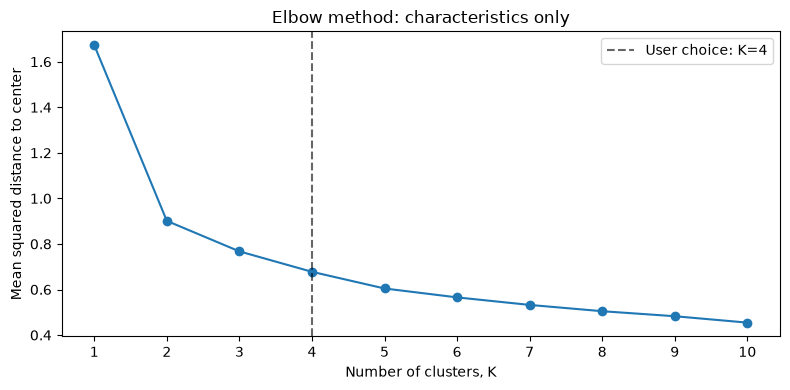

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diagnostics.index, diagnostics["mean_squared_distance"], marker="o")
ax.axvline(chosen_k, color="black", linestyle="--", alpha=0.6, label=f"User choice: K={chosen_k}")
ax.set(
    title="Elbow method: characteristics only",
    xlabel="Number of clusters, K",
    ylabel="Mean squared distance to center",
)
ax.set_xticks(list(candidate_ks))
ax.legend()

plt.tight_layout()
plt.show()

## Choosing K

We kept K=4 as a working reference for a more detailed interpretation, then compared full-data fits for K=2 and K=3 in Section 9. The score is part of the decision, not the whole decision.

# 5. Fit K=4

Fit all eligible products, then calculate silhouette on the same sample used above. This full-data fit is separate from the sample-fit candidates. Cluster numbers are labels, not a ranking of value.

In [6]:
with threadpool_limits(limits=1):
    model = KMeans(n_clusters=chosen_k, random_state=seed, n_init=10, max_iter=300)
    cohort["cluster"] = model.fit_predict(features)
    full_fit_sample_silhouette = silhouette_score(sample_features, model.predict(sample_features))

print("Full-cohort fit, silhouette on the fixed sample:", round(full_fit_sample_silhouette, 3))
print("Products assigned:", len(cohort), "| groups:", cohort["cluster"].nunique())

cohort.to_parquet(output_dir / "product_clusters.parquet", index=False)

Full-cohort fit, silhouette on the fixed sample: 0.224
Products assigned: 29877 | groups: 4


# 6. Describing the groups

The table shows group size and set age, followed by the three most common rarity and printing values. Percentages are within each group; the leading category need not be a majority.

These characteristics helped form the groups. Distinct card counts can overlap because different printings of one card may be in different groups.

In [7]:
characteristic_profiles = cohort.groupby("cluster").agg(
    products=("pc_id", "size"),
    distinct_cards=("card_id", "nunique"),
    median_set_age_years=("set_age_years", "median"),
    age_25th=("set_age_years", lambda values: values.quantile(0.25)),
    age_75th=("set_age_years", lambda values: values.quantile(0.75)),
)

display(characteristic_profiles.round(2))
characteristic_profiles.to_csv(output_dir / "characteristic_profiles.csv")

for field in ["rarity", "variant"]:
    counts = cohort.groupby(["cluster", field]).size().rename("products")
    category_profile = counts.to_frame()
    category_profile["within_cluster_pct"] = 100 * counts / counts.groupby(level=0).transform("sum")
    top = (
        category_profile.sort_values(["cluster", "products"], ascending=[True, False])
        .groupby(level=0)
        .head(3)
    )

    print("Most common", field, "values within each group:")
    display(top.round(1))

,products,distinct_cards,median_set_age_years,age_25th,age_75th
cluster,,,,,
0,6680,3445,21.56,19.83,23.50
1,9532,8851,4.81,2.51,6.58
2,5992,5929,5.08,2.76,7.32
3,7673,4381,13.81,11.81,16.08


Most common rarity values within each group:


products  within_cluster_pct
cluster rarity                                
0       Common        2147                32.1
        Uncommon      2025                30.3
        Rare          1208                18.1
1       Common        2149                22.5
        Uncommon      2076                21.8
        Rare          1084                11.4
2       Common        2202                36.7
        Uncommon      2168                36.2
        Rare          1005                16.8
3       Uncommon      2255                29.4
        Common        2254                29.4
        Rare          1462                19.1

Most common variant values within each group:


products  within_cluster_pct
cluster variant                                   
0       base              3362                50.3
        reverse-holo      1953                29.2
        1st-edition        916                13.7
1       base              8702                91.3
        holo               229                 2.4
        jumbo               92                 1.0
2       reverse-holo      5923                98.8
        toys-r-us           12                 0.2
        stamped              5                 0.1
3       base              4252                55.4
        reverse-holo      3059                39.9
        holo                62                 0.8

# 7. Compare prices

Now attach prices to the groups. A missing price doesn't change a product's assignment.

We first compare November 2024 ungraded prices, counting absent product-month rows separately from rows with no ungraded price.

We also calculate each product's median recorded price from December 2023 through November 2024. The number of recorded months stays with that median: one observation isn't a full year's history. Missing months, including October's gap, aren't filled.

In [8]:
panel = load_data()

november_prices = panel.loc[panel["month"] == snapshot_month, ["pc_id", "price_ungraded"]].copy()
november_prices["november_row_present"] = True
november_prices = november_prices.rename(columns={"price_ungraded": "november_ungraded_usd"})

window = panel.loc[
    panel["month"].between(summary_start, snapshot_month), ["pc_id", "month", "price_ungraded"]
]
year_prices = window.groupby("pc_id", as_index=False).agg(
    recorded_ungraded_months=("price_ungraded", "count"),
    year_median_ungraded_usd=("price_ungraded", "median"),
)

comparison = cohort.merge(november_prices, on="pc_id", how="left", validate="one_to_one")
comparison = comparison.merge(year_prices, on="pc_id", how="left", validate="one_to_one")

comparison["november_row_present"] = comparison["november_row_present"].eq(True)
comparison["recorded_ungraded_months"] = (
    comparison["recorded_ungraded_months"].fillna(0).astype(int)
)
comparison["no_november_row"] = ~comparison["november_row_present"]
comparison["november_row_missing_ungraded"] = (
    comparison["november_row_present"] & comparison["november_ungraded_usd"].isna()
)

price_profiles = comparison.groupby("cluster").agg(
    products=("pc_id", "size"),
    november_prices=("november_ungraded_usd", "count"),
    no_november_row=("no_november_row", "sum"),
    november_row_missing_ungraded=("november_row_missing_ungraded", "sum"),
    median_november_usd=("november_ungraded_usd", "median"),
    november_25th_usd=("november_ungraded_usd", lambda values: values.quantile(0.25)),
    november_75th_usd=("november_ungraded_usd", lambda values: values.quantile(0.75)),
    products_with_year_price=("year_median_ungraded_usd", "count"),
    median_of_year_medians_usd=("year_median_ungraded_usd", "median"),
)
price_profiles["november_coverage_pct"] = (
    100 * price_profiles["november_prices"] / price_profiles["products"]
)

print("November coverage in the clustered cohort:")
display(
    price_profiles[
        [
            "products",
            "november_prices",
            "no_november_row",
            "november_row_missing_ungraded",
            "november_coverage_pct",
        ]
    ].round(2)
)

print("Recorded price summaries (USD):")
display(
    price_profiles[
        [
            "median_november_usd",
            "november_25th_usd",
            "november_75th_usd",
            "products_with_year_price",
            "median_of_year_medians_usd",
        ]
    ].round(2)
)

print("Products by the number of recorded ungraded months in the 12-month window:")
display(
    pd.crosstab(comparison["recorded_ungraded_months"], comparison["cluster"]).reindex(
        range(13), fill_value=0
    )
)

price_profiles.to_csv(output_dir / "price_profiles.csv")
comparison.to_parquet(output_dir / "clusters_with_price_comparisons.parquet", index=False)

November coverage in the clustered cohort:


,products,november_prices,no_november_row,november_row_missing_ungraded,november_coverage_pct
cluster,,,,,
0,6680,6653,10,17,99.60
1,9532,9483,36,13,99.49
2,5992,5984,7,1,99.87
3,7673,7639,20,14,99.56


Recorded price summaries (USD):


,median_november_usd,november_25th_usd,november_75th_usd,products_with_year_price,median_of_year_medians_usd
cluster,,,,,
0,5.01,2.49,13.36,6653,5.00
1,1.50,1.10,3.31,9483,1.48
2,1.49,1.29,1.87,5985,1.42
3,2.19,1.53,3.85,7639,2.16


Products by the number of recorded ungraded months in the 12-month window:


cluster,0,1,2,3
recorded_ungraded_months,,,,
0,27,49,7,34
1,5,7,1,5
2,12,23,2,11
3,7,16,1,6
4,10,20,1,9
5,4,20,1,7
6,1,29,2,7
7,7,18,1,2
8,4,14,1,10


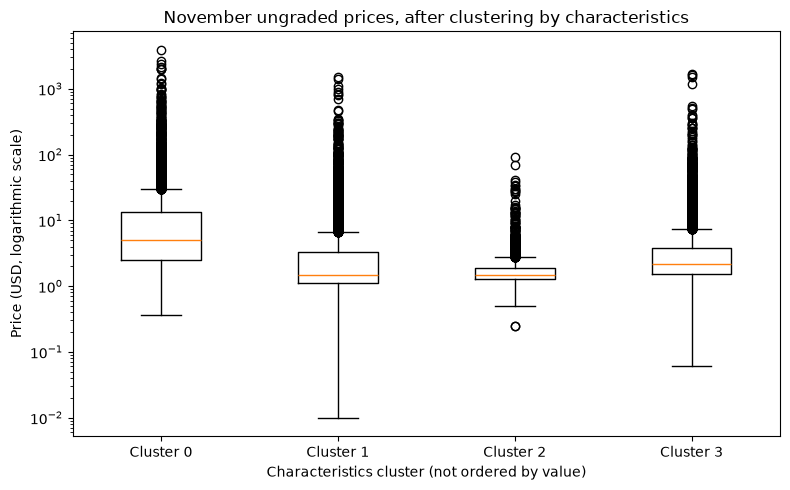

In [9]:
cluster_ids = sorted(comparison["cluster"].unique())
distributions = [
    comparison.loc[comparison["cluster"] == label, "november_ungraded_usd"].dropna().to_numpy()
    for label in cluster_ids
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(distributions, positions=range(len(cluster_ids)), showfliers=True)
ax.set_xticks(range(len(cluster_ids)), [f"Cluster {label}" for label in cluster_ids])
ax.set_yscale("log")
ax.set(
    title="November ungraded prices, after clustering by characteristics",
    xlabel="Characteristics cluster (not ordered by value)",
    ylabel="Price (USD, logarithmic scale)",
)

plt.tight_layout()
plt.show()

# 8. Observations from K=4

The groups mostly differ by release age and printing. Their price distributions overlap, so the groups aren't separate tiers where every card in one is worth more than every card in another.

The full-data fit has silhouette 0.224 on the fixed sample. We should read that alongside the group profiles rather than treat four groups as natural categories.

Price wasn't an input, so its relationship with the groups is worth examining. This still doesn't isolate what causes value. Grading is also separate here: the dataset has different price columns for grades, not the condition of one physical copy.

Results are saved under `results/characteristics_clustering/`. Rerunning replaces generated outputs, not the source data.


# 9. Comparing K=2, K=3, and K=4

We fit K=2 and K=3 on the same 29,877 products and three inputs, keeping the encoding, weights, seed, 10 starts, and 300 maximum iterations unchanged. The K=4 column reuses the saved reference assignments.

All three scores below evaluate full-data fits on the same 3,000-product sample. They are different from the earlier models fitted on that sample. Prices and the extra feature trials aren't inputs here.

K=4 remains the working reference while we compare the level of detail.

In [20]:
# K comparison: load and reconstruct the exact reference features
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

kcomp_root = Path("results/characteristics_clustering")
kcomp_output = kcomp_root / "k_comparison"
kcomp_output.mkdir(parents=True, exist_ok=True)

kcomp_reference = pd.read_parquet(kcomp_root / "product_clusters.parquet")
kcomp_saved_labels = kcomp_reference["cluster"].to_numpy()
kcomp_cohort = kcomp_reference.drop(columns="cluster").copy()

if not kcomp_cohort["pc_id"].is_unique or len(np.unique(kcomp_saved_labels)) != 4:
    raise ValueError("Expected a one-product-per-row reference with four saved groups.")

kcomp_age_scaler = StandardScaler()
kcomp_age = kcomp_age_scaler.fit_transform(kcomp_cohort[["set_age_years"]])

kcomp_encoder = OneHotEncoder(sparse_output=True, handle_unknown="error", dtype=np.float64)
kcomp_categories = kcomp_encoder.fit_transform(kcomp_cohort[["rarity", "variant"]])

kcomp_features = sparse.hstack(
    [
        sparse.csr_matrix(kcomp_age),
        kcomp_categories / np.sqrt(2),
    ],
    format="csr",
)

kcomp_sample_indices = np.random.default_rng(42).choice(
    len(kcomp_cohort), size=min(3000, len(kcomp_cohort)), replace=False
)

print("Products:", len(kcomp_cohort), "| distinct cards:", kcomp_cohort["card_id"].nunique())
print("Inputs: standardized set age, one-hot rarity and printing, with the original weights.")
print("Feature matrix:", kcomp_features.shape)

Products: 29877 | distinct cards: 16582
Inputs: standardized set age, one-hot rarity and printing, with the original weights.
Feature matrix: (29877, 272)


In [21]:
# K comparison: fit two and three groups; retain the saved four-group assignments
kcomp_labels = {4: kcomp_saved_labels}
kcomp_models = {}

with threadpool_limits(limits=1):
    for k in [2, 3]:
        estimator = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
        kcomp_labels[k] = estimator.fit_predict(kcomp_features)
        kcomp_models[k] = estimator

    kcomp_diagnostics = pd.DataFrame(
        [
            {
                "k": k,
                "products_fitted": len(kcomp_cohort),
                "products_in_score_sample": len(kcomp_sample_indices),
                "full_fit_sample_silhouette": silhouette_score(
                    kcomp_features[kcomp_sample_indices], kcomp_labels[k][kcomp_sample_indices]
                ),
                "assignments_from": "saved K=4 reference" if k == 4 else "new full-cohort fit",
            }
            for k in [2, 3, 4]
        ]
    ).set_index("k")

display(kcomp_diagnostics.round(3))
kcomp_diagnostics.to_csv(kcomp_output / "diagnostics.csv")

for k in [2, 3, 4]:
    saved_assignments = kcomp_cohort.copy()
    saved_assignments["cluster"] = kcomp_labels[k]
    saved_assignments.to_parquet(kcomp_output / f"k{k}_assignments.parquet", index=False)

,products_fitted,products_in_score_sample,full_fit_sample_silhouette,assignments_from
k,,,,
2,29877,3000,0.383,new full-cohort fit
3,29877,3000,0.290,new full-cohort fit
4,29877,3000,0.224,saved K=4 reference


## What do the groups look like?

Each model's groups are shown in order of median set age. Cluster 0 at one K isn't necessarily the same group as cluster 0 at another K.

We describe the input characteristics first, then attach the same recorded prices. Products without prices still belong to their groups.

In [22]:
# K comparison: describe the groups and attach the same price observations
kcomp_price_source = pd.read_parquet(kcomp_root / "clusters_with_price_comparisons.parquet")

if set(kcomp_price_source["pc_id"]) != set(kcomp_cohort["pc_id"]):
    raise ValueError("Saved price comparison and reference cohort have different product IDs.")

kcomp_prices = kcomp_price_source[
    [
        "pc_id",
        "november_ungraded_usd",
        "year_median_ungraded_usd",
        "recorded_ungraded_months",
        "no_november_row",
        "november_row_missing_ungraded",
    ]
]

kcomp_priced = {}
kcomp_profile_rows = []

for k in [2, 3, 4]:
    frame = kcomp_cohort.assign(cluster=kcomp_labels[k]).merge(
        kcomp_prices, on="pc_id", how="left", validate="one_to_one"
    )
    kcomp_priced[k] = frame

    for cluster, products_in_group in frame.groupby("cluster"):
        printings = products_in_group["variant"].value_counts()
        rarities = products_in_group["rarity"].value_counts()
        prices = products_in_group["november_ungraded_usd"]

        kcomp_profile_rows.append(
            {
                "k": k,
                "cluster": cluster,
                "products": len(products_in_group),
                "distinct_cards": products_in_group["card_id"].nunique(),
                "median_set_age_years": products_in_group["set_age_years"].median(),
                "age_25th_years": products_in_group["set_age_years"].quantile(0.25),
                "age_75th_years": products_in_group["set_age_years"].quantile(0.75),
                "leading_printing": f"{printings.index[0]} ({100 * printings.iloc[0] / len(products_in_group):.1f}%)",
                "leading_rarity": f"{rarities.index[0]} ({100 * rarities.iloc[0] / len(products_in_group):.1f}%)",
                "recorded_november_prices": prices.count(),
                "no_november_row": products_in_group["no_november_row"].sum(),
                "november_row_missing_ungraded": products_in_group[
                    "november_row_missing_ungraded"
                ].sum(),
                "median_november_usd": prices.median(),
                "price_25th_usd": prices.quantile(0.25),
                "price_75th_usd": prices.quantile(0.75),
                "products_with_year_price": products_in_group["year_median_ungraded_usd"].count(),
                "median_of_year_medians_usd": products_in_group[
                    "year_median_ungraded_usd"
                ].median(),
            }
        )

kcomp_profiles = pd.DataFrame(kcomp_profile_rows).set_index(["k", "cluster"])
kcomp_profiles.to_csv(kcomp_output / "group_profiles.csv")

for k in [2, 3, 4]:
    print(f"K={k}: groups ordered by median set age")
    display(
        kcomp_profiles.loc[k]
        .sort_values("median_set_age_years")[
            [
                "products",
                "median_set_age_years",
                "leading_printing",
                "leading_rarity",
                "recorded_november_prices",
            ]
        ]
        .round(2)
    )

K=2: groups ordered by median set age


,products,median_set_age_years,leading_printing,leading_rarity,recorded_november_prices
cluster,,,,,
0,17958,5.33,base (57.5%),Common (27.7%),17891
1,11919,18.58,base (50.3%),Common (31.6%),11868


K=3: groups ordered by median set age


,products,median_set_age_years,leading_printing,leading_rarity,recorded_november_prices
cluster,,,,,
0,11361,5.27,base (92.0%),Common (22.8%),11306
2,7202,5.83,reverse-holo (98.6%),Common (35.9%),7190
1,11314,19.08,base (51.8%),Common (31.6%),11263


K=4: groups ordered by median set age


,products,median_set_age_years,leading_printing,leading_rarity,recorded_november_prices
cluster,,,,,
1,9532,4.81,base (91.3%),Common (22.5%),9483
2,5992,5.08,reverse-holo (98.8%),Common (36.7%),5984
3,7673,13.81,base (55.4%),Uncommon (29.4%),7639
0,6680,21.56,base (50.3%),Common (32.1%),6653


## Price distributions and group overlap

All panels use the same November observations and log-scale USD axis. Boxes show the median and middle 50%; points beyond the whiskers are retained, not assumed to be errors.

Groups are ordered by set age. A larger K can regroup products, not just split the previous groups, so we also check the overlap tables.

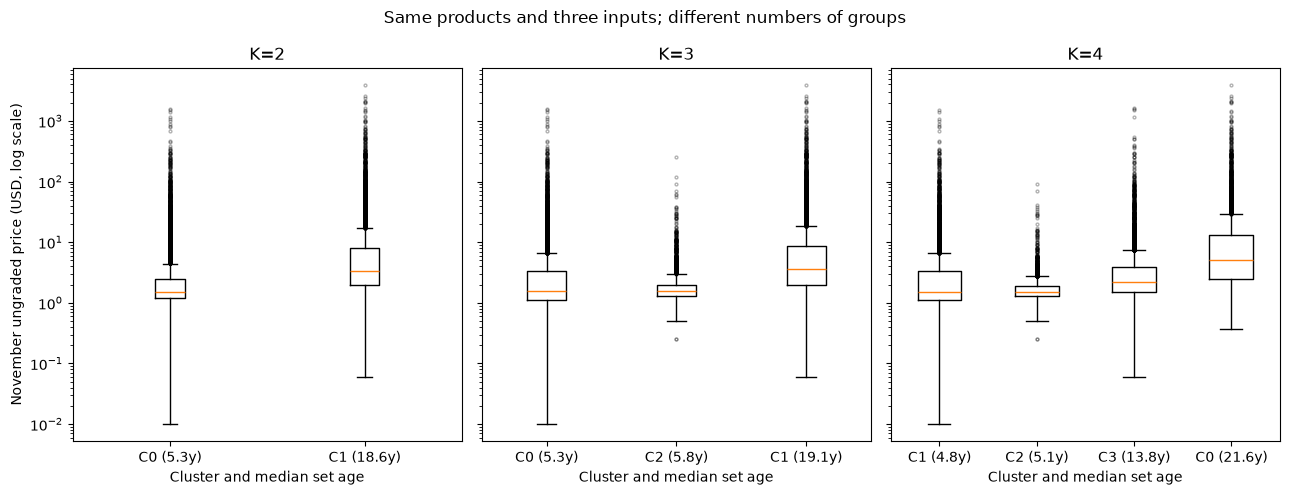

Product overlap: K=2 versus K=3


K=3 cluster,0,1,2
K=2 cluster,,,
0,11234,10,6714
1,127,11304,488


Product overlap: K=3 versus K=4


K=4 cluster,0,1,2,3
K=3 cluster,,,,
0,0,9532,8,1821
1,6680,0,0,4634
2,0,0,5984,1218


In [24]:
# K comparison: visualize outcomes and inspect overlap between solutions
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, k in zip(axes, [2, 3, 4]):
    ordered = kcomp_profiles.loc[k].sort_values("median_set_age_years")
    distributions = [
        kcomp_priced[k]
        .loc[kcomp_priced[k]["cluster"].eq(cluster), "november_ungraded_usd"]
        .dropna()
        .to_numpy()
        for cluster in ordered.index
    ]

    ax.boxplot(
        distributions,
        positions=range(k),
        showfliers=True,
        flierprops={"markersize": 2, "alpha": 0.3},
    )
    ax.set_xticks(
        range(k),
        [
            f"C{cluster} ({age:.1f}y)"
            for cluster, age in zip(ordered.index, ordered["median_set_age_years"])
        ],
    )
    ax.set_yscale("log")
    ax.set_title(f"K={k}")
    ax.set_xlabel("Cluster and median set age")

axes[0].set_ylabel("November ungraded price (USD, log scale)")
fig.suptitle("Same products and three inputs; different numbers of groups")
plt.tight_layout()
plt.show()

for smaller_k, larger_k in [(2, 3), (3, 4)]:
    overlap = pd.crosstab(
        kcomp_labels[smaller_k],
        kcomp_labels[larger_k],
        rownames=[f"K={smaller_k} cluster"],
        colnames=[f"K={larger_k} cluster"],
    )

    print(f"Product overlap: K={smaller_k} versus K={larger_k}")
    display(overlap)
    overlap.to_csv(kcomp_output / f"overlap_k{smaller_k}_k{larger_k}.csv")

## Observations

- **K=2:** mainly newer versus older products, with printings mixed inside each.
- **K=3:** separates newer base and reverse-holo products and keeps an older mixed-printing group. Both newer groups have median price $1.55, but their spreads differ.
- **K=4:** retains that printing distinction and adds more age detail, including middle-era and oldest groups.

K=2 has the highest silhouette of these fits. K=3 and K=4 give more detail, so the choice also depends on whether those distinctions help answer our question. K=4 is still the working reference.

The comparison is saved under `results/characteristics_clustering/k_comparison/`.
`Clustering_History_Interpretation.ipynb` follows these fixed groups through the
price history and checks matched cards and printings, rather than relying on
group medians alone.

# Appendix A: adding subtypes

We tested subtypes on the same products, with K=4 and the other feature weights unchanged.

Subtypes are lists such as `["Basic", "V"]`. We keep the labels separate, ignore list order, and preserve case (`EX` and `ex` aren't merged). An empty list means the source list was empty—not that we know the card has no applicable subtype.

Missing or malformed lists need review rather than guessed labels or silent exclusions.

In [10]:
import json

from sklearn.preprocessing import MultiLabelBinarizer, normalize
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

subtype_dir = output_dir / "with_subtypes"
subtype_dir.mkdir(parents=True, exist_ok=True)

subtype_cohort = cohort.merge(
    cards[["card_id", "supertype", "subtypes"]],
    on="card_id",
    how="left",
    validate="many_to_one",
).rename(columns={"cluster": "baseline_cluster"})

if not subtype_cohort["pc_id"].equals(cohort["pc_id"]):
    raise ValueError("Product order changed; review feature alignment before clustering.")


def parse_subtype_list(raw):
    if not isinstance(raw, str) or not raw.strip():
        raise ValueError("Missing subtype list: review before a same-cohort comparison.")

    values = json.loads(raw)
    if not isinstance(values, list) or any(
        not isinstance(label, str) or not label.strip() for label in values
    ):
        raise ValueError("Expected a JSON list of nonblank subtype labels.")

    return sorted(set(values))


subtype_cohort["subtype_labels"] = subtype_cohort["subtypes"].map(parse_subtype_list)
subtype_cohort["source_subtypes_empty"] = subtype_cohort["subtype_labels"].map(len).eq(0)

subtype_audit = subtype_cohort[["pc_id", "card_id", "supertype", "source_subtypes_empty"]].copy()
subtype_audit["recorded_labels"] = subtype_cohort["subtype_labels"].map(len)
subtype_audit.to_csv(subtype_dir / "subtype_audit.csv", index=False)

print("Products in both experiments:", len(subtype_cohort))
print("Explicit empty source lists in this cohort:", subtype_cohort["source_subtypes_empty"].sum())
print("Number of recorded subtype labels per product:")
display(subtype_audit["recorded_labels"].value_counts().sort_index().rename("products").to_frame())

print("Examples of source lists:")
display(subtype_cohort[["name", "supertype", "subtypes"]].drop_duplicates("subtypes").head(12))

Products in both experiments: 29877
Explicit empty source lists in this cohort: 355
Number of recorded subtype labels per product:


,products
recorded_labels,
0,355
1,26328
2,2827
3,355
4,12


Examples of source lists:


,name,supertype,subtypes
0,Corviknight,Pokémon,"[""Stage 2""]"
1,Alolan Sandslash,Pokémon,"[""Stage 1""]"
3,Professor Kukui,Trainer,"[""Supporter""]"
4,Galarian Sirfetch'd V,Pokémon,"[""Basic"", ""V""]"
7,Chansey,Pokémon,"[""Basic""]"
73,Clefairy Doll,Trainer,[]
98,Double Colorless Energy,Energy,"[""Special""]"
398,Digger,Trainer,"[""Rocket's Secret Machine""]"
599,No Removal Gym,Trainer,"[""Stadium""]"
824,Pichu,Pokémon,"[""Baby""]"


## A1. Encoding the lists

Each subtype gets a yes/no column, with a separate indicator for an empty source list. We normalize each product's subtype vector, then divide by `sqrt(2)`.

At this weight, disjoint subtype lists have the same distance as one rarity or printing mismatch; shared labels reduce the distance. A longer list doesn't get a larger vector just for containing more labels.

In [11]:
subtype_encoder = MultiLabelBinarizer(sparse_output=True)
subtype_binary = subtype_encoder.fit_transform(subtype_cohort["subtype_labels"])

empty_indicator = sparse.csr_matrix(
    subtype_cohort["source_subtypes_empty"].to_numpy(dtype=np.float64).reshape(-1, 1)
)

subtype_block = (
    normalize(sparse.hstack([subtype_binary, empty_indicator], format="csr"), norm="l2")
    * category_mismatch_distance
    / np.sqrt(2)
)
features_with_subtypes = sparse.hstack([features, subtype_block], format="csr")

print("Distinct subtype labels:", len(subtype_encoder.classes_))
print("Baseline feature matrix:", features.shape)
print("Feature matrix with subtypes:", features_with_subtypes.shape)
print("Additional products excluded:", len(cohort) - len(subtype_cohort))

Distinct subtype labels: 41
Baseline feature matrix: (29877, 272)
Feature matrix with subtypes: (29877, 314)
Additional products excluded: 0


## A2. Checking separation

Use the same sample, K values, seed, and fitting settings as the reference. The distance now includes subtypes, so a change in silhouette or inertia isn't by itself evidence of a better price analysis.

,three_feature_baseline,with_subtypes
k,,
2,0.383,0.321
3,0.290,0.225
4,0.225,0.162
5,0.251,0.181
6,0.234,0.185
7,0.241,0.190
8,0.235,0.181
9,0.237,0.194
10,0.252,0.206


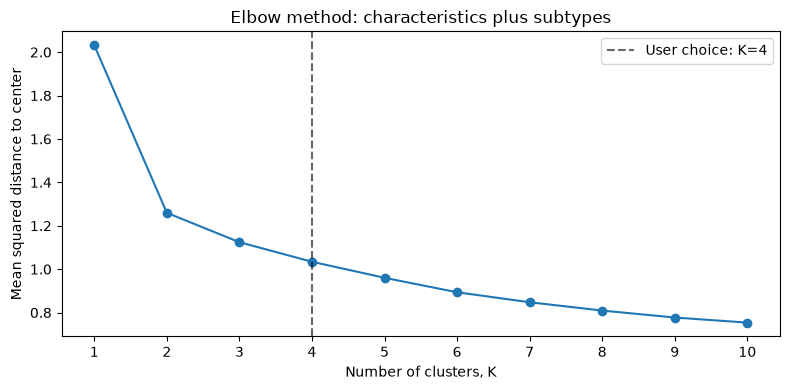

In [12]:
subtype_sample = features_with_subtypes[sample_indices]
subtype_diagnostic_rows = []

with threadpool_limits(limits=1):
    for k in candidate_ks:
        candidate = KMeans(n_clusters=k, random_state=seed, n_init=10, max_iter=300)
        labels = candidate.fit_predict(subtype_sample)

        subtype_diagnostic_rows.append(
            {
                "k": k,
                "sample_products": len(sample_indices),
                "mean_squared_distance": candidate.inertia_ / len(sample_indices),
                "sample_silhouette": silhouette_score(subtype_sample, labels) if k > 1 else np.nan,
            }
        )

subtype_diagnostics = pd.DataFrame(subtype_diagnostic_rows).set_index("k")
subtype_diagnostics.to_csv(subtype_dir / "k_diagnostics.csv")

silhouette_comparison = pd.DataFrame(
    {
        "three_feature_baseline": diagnostics["sample_silhouette"],
        "with_subtypes": subtype_diagnostics["sample_silhouette"],
    }
)

display(silhouette_comparison.loc[2:].round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(subtype_diagnostics.index, subtype_diagnostics["mean_squared_distance"], marker="o")
ax.axvline(chosen_k, color="black", linestyle="--", alpha=0.6, label=f"User choice: K={chosen_k}")
ax.set(
    title="Elbow method: characteristics plus subtypes",
    xlabel="Number of clusters, K",
    ylabel="Mean squared distance to center",
)
ax.set_xticks(list(candidate_ks))
ax.legend()

plt.tight_layout()
plt.show()

## A3. Comparing assignments

Fit K=4 with subtypes. Cluster numbers can be swapped between models, so we use ARI to compare grouping agreement and match labels before counting changed assignments. This isn't independent validation.

In [13]:
with threadpool_limits(limits=1):
    subtype_model = KMeans(n_clusters=chosen_k, random_state=seed, n_init=10, max_iter=300)
    subtype_cohort["cluster"] = subtype_model.fit_predict(features_with_subtypes)
    subtype_full_fit_silhouette = silhouette_score(
        subtype_sample, subtype_model.predict(subtype_sample)
    )

print("K:", chosen_k, "| products:", len(subtype_cohort))
print("Full-fit silhouettes evaluated on the same products, in each model space:")
display(
    pd.DataFrame(
        {
            "three_feature_baseline": [full_fit_sample_silhouette],
            "with_subtypes": [subtype_full_fit_silhouette],
        },
        index=["sample_silhouette"],
    ).round(3)
)

agreement_with_baseline = adjusted_rand_score(
    subtype_cohort["baseline_cluster"], subtype_cohort["cluster"]
)
print("ARI compared with the baseline:", round(agreement_with_baseline, 3))

assignment_overlap = pd.crosstab(
    subtype_cohort["baseline_cluster"],
    subtype_cohort["cluster"],
    rownames=["baseline cluster"],
    colnames=["cluster with subtypes"],
)
display(assignment_overlap)

matched_rows, matched_columns = linear_sum_assignment(assignment_overlap.to_numpy(), maximize=True)
different_products = (
    len(subtype_cohort) - assignment_overlap.to_numpy()[matched_rows, matched_columns].sum()
)
print("Different assignments after matching label numbers:", different_products)

subtype_cohort.to_parquet(subtype_dir / "product_clusters.parquet", index=False)

K: 4 | products: 29877
Full-fit silhouettes evaluated on the same products, in each model space:


,three_feature_baseline,with_subtypes
sample_silhouette,0.224,0.162


ARI compared with the baseline: 0.973


cluster with subtypes,0,1,2,3
baseline cluster,,,,
0,77,0,6603,0
1,14,9516,0,2
2,49,38,0,5905
3,7539,54,80,0


Different assignments after matching label numbers: 314


### Updated group profiles

A product can have several subtypes. Percentages use all products in that group as the denominator, so subtype percentages can add to more than 100%. Empty lists are shown separately from actual labels.

In [14]:
subtype_characteristic_profiles = subtype_cohort.groupby("cluster").agg(
    products=("pc_id", "size"),
    distinct_cards=("card_id", "nunique"),
    median_set_age_years=("set_age_years", "median"),
    age_25th=("set_age_years", lambda values: values.quantile(0.25)),
    age_75th=("set_age_years", lambda values: values.quantile(0.75)),
    empty_source_lists=("source_subtypes_empty", "sum"),
)

display(subtype_characteristic_profiles.round(2))
subtype_characteristic_profiles.to_csv(subtype_dir / "characteristic_profiles.csv")

for field in ["rarity", "variant"]:
    counts = subtype_cohort.groupby(["cluster", field]).size().rename("products")
    profile = counts.to_frame()
    profile["within_cluster_pct"] = 100 * counts / counts.groupby(level=0).transform("sum")

    print("Most common", field, "values:")
    display(
        profile.sort_values(["cluster", "products"], ascending=[True, False])
        .groupby(level=0)
        .head(3)
        .round(1)
    )

label_rows = subtype_cohort[["cluster", "subtype_labels"]].copy()
label_rows["subtype_labels"] = label_rows["subtype_labels"].map(
    lambda labels: labels if labels else ["(source list empty)"]
)

counts = (
    label_rows.explode("subtype_labels")
    .groupby(["cluster", "subtype_labels"])
    .size()
    .rename("products")
)
subtype_profile = counts.to_frame()
subtype_profile["within_cluster_pct"] = (
    100
    * counts
    / counts.index.get_level_values("cluster").map(subtype_characteristic_profiles["products"])
)

print("Most common subtype labels (products may have several):")
display(
    subtype_profile.sort_values(["cluster", "products"], ascending=[True, False])
    .groupby(level=0)
    .head(5)
    .round(1)
)

subtype_profile.to_csv(subtype_dir / "subtype_profiles.csv")

,products,distinct_cards,median_set_age_years,age_25th,age_75th,empty_source_lists
cluster,,,,,,
0,7679,4354,13.81,11.81,16.08,0
1,9608,8897,4.81,2.51,6.83,1
2,6683,3453,21.56,19.83,23.50,354
3,5907,5887,5.08,2.76,7.32,0


Most common rarity values:


products  within_cluster_pct
cluster rarity                                
0       Common        2375                30.9
        Uncommon      2187                28.5
        Rare          1456                19.0
1       Common        2142                22.3
        Uncommon      2135                22.2
        Rare          1092                11.4
2       Common        2084                31.2
        Uncommon      2063                30.9
        Rare          1209                18.1
3       Common        2151                36.4
        Uncommon      2139                36.2
        Rare          1002                17.0

Most common variant values:


products  within_cluster_pct
cluster variant                                   
0       base              4198                54.7
        reverse-holo      3100                40.4
        holo                67                 0.9
1       base              8742                91.0
        holo               232                 2.4
        jumbo               92                 1.0
2       base              3376                50.5
        reverse-holo      1948                29.1
        1st-edition        916                13.7
3       reverse-holo      5887                99.7
        toys-r-us            4                 0.1
        build-a-bear         3                 0.1

Most common subtype labels (products may have several):


products  within_cluster_pct
cluster subtype_labels                                   
0       Basic                    3932                51.2
        Stage 1                  2095                27.3
        Stage 2                   693                 9.0
        Item                      363                 4.7
        EX                        241                 3.1
1       Basic                    4641                48.3
        Stage 1                  2115                22.0
        Stage 2                   791                 8.2
        Supporter                 776                 8.1
        V                         649                 6.8
2       Basic                    2903                43.4
        Stage 1                  1995                29.9
        Stage 2                   706                10.6
        (source list empty)       354                 5.3
        Item                      149                 2.2
3       Basic                    2803                47.5
        Stage 1                  1685                28.5
        Stage 2                   463                 7.8
        Item                      332                 5.6
        Supporter                 332                 5.6

## A4. Prices after adding subtypes

Attach the same November prices and recorded 12-month medians as before. Prices still aren't part of eligibility or fitting.

In [15]:
subtype_prices = comparison.rename(columns={"cluster": "baseline_cluster"}).merge(
    subtype_cohort[["pc_id", "cluster"]], on="pc_id", how="left", validate="one_to_one"
)

subtype_price_profiles = subtype_prices.groupby("cluster").agg(
    products=("pc_id", "size"),
    november_prices=("november_ungraded_usd", "count"),
    no_november_row=("no_november_row", "sum"),
    november_row_missing_ungraded=("november_row_missing_ungraded", "sum"),
    median_november_usd=("november_ungraded_usd", "median"),
    november_25th_usd=("november_ungraded_usd", lambda values: values.quantile(0.25)),
    november_75th_usd=("november_ungraded_usd", lambda values: values.quantile(0.75)),
    products_with_year_price=("year_median_ungraded_usd", "count"),
    median_of_year_medians_usd=("year_median_ungraded_usd", "median"),
)

subtype_price_profiles["november_coverage_pct"] = (
    100 * subtype_price_profiles["november_prices"] / subtype_price_profiles["products"]
)

display(subtype_price_profiles.round(2))
subtype_price_profiles.to_csv(subtype_dir / "price_profiles.csv")
subtype_prices.to_parquet(subtype_dir / "clusters_with_price_comparisons.parquet", index=False)

,products,november_prices,no_november_row,november_row_missing_ungraded,median_november_usd,november_25th_usd,november_75th_usd,products_with_year_price,median_of_year_medians_usd,november_coverage_pct
cluster,,,,,,,,,,
0,7679,7646,19,14,2.19,1.53,3.86,7646,2.15,99.57
1,9608,9555,39,14,1.51,1.10,3.36,9556,1.48,99.45
2,6683,6655,11,17,5.00,2.49,13.32,6655,5.00,99.58
3,5907,5903,4,0,1.49,1.29,1.86,5903,1.42,99.93


### Observations

Adding subtypes changed 314 of the 29,877 assignments after matching labels, with ARI 0.973. Most of the grouping stayed the same, and corresponding group price medians were similar.

Silhouette fell from 0.224 to 0.162, but the distance definition changed too. This doesn't prove that subtypes are unrelated to value; they made little difference to this particular grouping.

Subtype results are saved in `results/characteristics_clustering/with_subtypes/`, separate from the reference.

## A5. Which products changed groups?

A changed assignment here isn't a price change over time. We match groups by membership overlap and call the reference groups A–D. These letters aren't value rankings. The following inspection reads the saved assignments.

In [16]:
# Inspection: load saved assignments
from pathlib import Path

import pandas as pd
import numpy as np
from scipy.optimize import linear_sum_assignment

inspection_root = Path("results/characteristics_clustering/with_subtypes")
inspection_output = inspection_root / "inspection"
inspection_output.mkdir(parents=True, exist_ok=True)

inspected_products = pd.read_parquet(inspection_root / "product_clusters.parquet")
inspection_prices = pd.read_parquet(inspection_root / "clusters_with_price_comparisons.parquet")
inspected_products = inspected_products.merge(
    inspection_prices[["pc_id", "november_ungraded_usd", "year_median_ungraded_usd"]],
    on="pc_id",
    how="left",
    validate="one_to_one",
)

inspection_overlap = pd.crosstab(
    inspected_products["baseline_cluster"], inspected_products["cluster"]
)
row_match, column_match = linear_sum_assignment(inspection_overlap.to_numpy(), maximize=True)

group_letters = {
    label: chr(ord("A") + i) for i, label in enumerate(sorted(inspection_overlap.index))
}
new_to_old = {
    inspection_overlap.columns[column]: inspection_overlap.index[row]
    for row, column in zip(row_match, column_match)
}

inspected_products["from_group"] = inspected_products["baseline_cluster"].map(group_letters)
inspected_products["to_group"] = inspected_products["cluster"].map(new_to_old).map(group_letters)
inspected_products["changed_group"] = inspected_products["from_group"].ne(
    inspected_products["to_group"]
)

label_mapping = (
    pd.DataFrame(
        [
            {
                "group": group_letters[old],
                "baseline_cluster_number": old,
                "subtype_cluster_number": new,
            }
            for new, old in new_to_old.items()
        ]
    )
    .sort_values("group")
    .set_index("group")
)

display(label_mapping)
print("Products:", len(inspected_products))
print("Genuinely different assignments after matching:", inspected_products["changed_group"].sum())

,baseline_cluster_number,subtype_cluster_number
group,,
A,0,2
B,1,1
C,2,3
D,3,0


Products: 29877
Genuinely different assignments after matching: 314


### Describing A–D

These are the groups after adding subtypes. Age is measured at November 2024, and price medians use recorded November values. The most common printing describes a group; it isn't a membership rule.

In [17]:
# Inspection: describe aligned groups
group_summary_rows = []

for group, products_in_group in inspected_products.groupby("to_group"):
    printing_counts = products_in_group["variant"].value_counts()
    printing = printing_counts.index[0]
    share = 100 * printing_counts.iloc[0] / len(products_in_group)

    group_summary_rows.append(
        {
            "group": group,
            "products": len(products_in_group),
            "median_set_age_years": products_in_group["set_age_years"].median(),
            "leading_printing": f"{printing} ({share:.1f}%)",
            "recorded_november_prices": products_in_group["november_ungraded_usd"].count(),
            "median_november_usd": products_in_group["november_ungraded_usd"].median(),
        }
    )

inspection_group_summary = pd.DataFrame(group_summary_rows).set_index("group")

display(inspection_group_summary.round(2))
inspection_group_summary.to_csv(inspection_output / "aligned_group_profiles.csv")

print("Card types within each group (% of that group):")
display(
    pd.crosstab(inspected_products["to_group"], inspected_products["supertype"], normalize="index")
    .mul(100)
    .round(1)
)

,products,median_set_age_years,leading_printing,recorded_november_prices,median_november_usd
group,,,,,
A,6683,21.56,base (50.5%),6655,5.00
B,9608,4.81,base (91.0%),9555,1.51
C,5907,5.08,reverse-holo (99.7%),5903,1.49
D,7679,13.81,base (54.7%),7646,2.19


Card types within each group (% of that group):


supertype,Energy,Pokémon,Trainer
to_group,,,
A,2.6,83.8,13.6
B,1.6,82.7,15.7
C,1.3,83.6,15.0
D,1.7,88.8,9.5


Age and printing still give the clearest short descriptions. There isn't a separate V-only or EX-only group at this K and weight. A group's median price doesn't describe every member.


## A6. Card type matters

`Basic` and `Stage 1` describe Pokémon stages; `Item` and `Supporter` describe Trainers. Basic Energy also uses `Basic`. Our shared-label encoding can therefore put different meanings in one column.

We inspect subtype frequencies within each card type before interpreting them as a value pattern. The encoding hasn't been changed in this check.

In [18]:
# Inspection: profile subtypes within card types
type_changes = inspected_products.groupby("supertype").agg(
    products=("pc_id", "size"), changed_assignments=("changed_group", "sum")
)
type_changes["changed_pct"] = 100 * type_changes["changed_assignments"] / type_changes["products"]

display(type_changes.round(2))
type_changes.to_csv(inspection_output / "changes_by_supertype.csv")

label_inspection = inspected_products[["supertype", "subtype_labels", "changed_group"]].copy()
label_inspection["subtype_label"] = label_inspection["subtype_labels"].map(
    lambda labels: list(labels) if len(labels) else ["(source list empty)"]
)
label_inspection = label_inspection.explode("subtype_label")

labels_by_type = (
    label_inspection.groupby(["supertype", "subtype_label"]).size().rename("products").to_frame()
)
type_totals = inspected_products.groupby("supertype").size()
labels_by_type["within_type_pct"] = (
    100
    * labels_by_type["products"]
    / labels_by_type.index.get_level_values("supertype").map(type_totals)
)

print("Three most common subtype labels within each card type:")
display(
    labels_by_type.sort_values(["supertype", "products"], ascending=[True, False])
    .groupby(level=0)
    .head(3)
    .round(2)
)
labels_by_type.to_csv(inspection_output / "subtype_prevalence_by_supertype.csv")

print("Empty source subtype lists by card type:")
display(
    inspected_products.groupby("supertype")["source_subtypes_empty"]
    .sum()
    .rename("products")
    .to_frame()
)

,products,changed_assignments,changed_pct
supertype,,,
Energy,532,10,1.88
Pokémon,25307,243,0.96
Trainer,4038,61,1.51


Three most common subtype labels within each card type:


products  within_type_pct
supertype subtype_label                           
Energy    Special             363            68.23
          Basic               169            31.77
          Single Strike         6             1.13
Pokémon   Basic             14110            55.76
          Stage 1            7890            31.18
          Stage 2            2653            10.48
Trainer   Supporter          1450            35.91
          Item               1279            31.67
          Pokémon Tool        516            12.78

Empty source subtype lists by card type:


,products
supertype,
Energy,0
Pokémon,0
Trainer,355


Subtype percentages can exceed 100% because products can have several labels. Empty source lists stay marked rather than filled with an assumed subtype.

## A7. Examples of changed assignments

For each card type, use its largest change route and select a product nearest that route's median set age, breaking ties by product ID. Price isn't used to choose the examples.

In [19]:
# Inspection: inspect movement routes and examples
changed_products = inspected_products.loc[inspected_products["changed_group"]].copy()
routes = (
    changed_products.groupby(["from_group", "to_group"])
    .size()
    .rename("products")
    .sort_values(ascending=False)
)

display(routes.to_frame())

example_rows = []

for supertype, changed_type in changed_products.groupby("supertype"):
    type_routes = (
        changed_type.groupby(["from_group", "to_group"]).size().sort_values(ascending=False)
    )
    start, end = type_routes.index[0]

    candidates = changed_type.loc[
        changed_type["from_group"].eq(start) & changed_type["to_group"].eq(end)
    ].copy()

    candidates["distance_from_route_median_age"] = (
        candidates["set_age_years"] - candidates["set_age_years"].median()
    ).abs()
    example_rows.append(candidates.sort_values(["distance_from_route_median_age", "pc_id"]).iloc[0])

example_products = pd.DataFrame(example_rows)
example_products["product"] = example_products["name"] + " [" + example_products["variant"] + "]"
example_products["assignment_change"] = (
    example_products["from_group"] + " → " + example_products["to_group"]
)

display(
    example_products[
        [
            "product",
            "supertype",
            "subtypes",
            "set_age_years",
            "assignment_change",
            "november_ungraded_usd",
        ]
    ].round(2)
)

changed_products[
    [
        "pc_id",
        "card_id",
        "name",
        "supertype",
        "rarity",
        "variant",
        "set_name",
        "subtypes",
        "set_age_years",
        "from_group",
        "to_group",
        "november_ungraded_usd",
        "year_median_ungraded_usd",
    ]
].to_csv(inspection_output / "changed_products.csv", index=False)
example_products[
    [
        "pc_id",
        "name",
        "supertype",
        "variant",
        "set_name",
        "subtypes",
        "set_age_years",
        "from_group",
        "to_group",
        "november_ungraded_usd",
    ]
].to_csv(inspection_output / "selected_examples.csv", index=False)

products
from_group to_group          
D          A               80
A          D               77
D          B               54
C          D               49
           B               38
B          D               14
           C                2

,product,supertype,subtypes,set_age_years,assignment_change,november_ungraded_usd
1237,Double Rainbow Energy [base],Energy,"[""Special""]",17.75,D → A,6.07
8278,Aron [base],Pokémon,"[""Basic""]",17.83,A → D,1.65
13718,Acro Bike [base],Trainer,"[""Item""]",9.82,D → B,1.40


Aron's base printing from Power Keepers moves from A to D between models, but its recorded November price stays $1.65. The new distances and refitted centers changed its neighbors, not its market value.

The inspection also shows that all 355 empty subtype lists in this sample belong to Trainers. We haven't guessed replacements.

These examples help explain the model. They don't establish a subtype's effect on price. The reference and subtype assignments are both retained for comparison.
